# Strip waveguide directional coupler - FDTD
This notebook contains code that simulates **classic directional coupler consisting strip waveguides** using **Lumerical FDTD** solver and **lumapi** interface. \
The objective is to obtain field propagation through the structure and extract S-parameters.

In [1]:
%%capture

# Install dependencies specified in pyproject.toml
!uv pip install -r pyproject.toml

%matplotlib widget

# Standard library imports
from datetime import datetime
import math

# Import modules
from IPython.display import display
import lumapi as lma
import matplotlib.pyplot as plt
import numpy as np
import photonix as px

In [2]:
%%html

<!-- Align table to the left -->
<style>
  table {margin-left: 0 !important;}
</style>

In [3]:
# Constants

um = 1e-6
nm = 1e-9
C = 299792458

# Simulation input

| Parameter                   | Description                                                                   | Example                                                      |
| :-------------------------- | :-----------------------------------------------------------------------------| :------------------------------------------------------------|
| **wavelength_center**       | Wavelength for which simulation will be done.                                 | `1.55*um`                                                    |
| **wavelength_span**         | Span of the wavelength for which simulation will be done.                     | `0.14*um`                                                    |
| **coupler_gap**             | Gap width of directional coupler                                              | `400*nm`                                                     |
| **coupler_length**          | Length of directional coupler                                                 | `12.15*um`                                                   |
| **s_bend_gds**              | Path to GDS file containing connector waveguide (S-bend)                      | `/workspace/GDS/si3n4_w1000nm_h360nm_sbendGA_w5um_l20um.gds` |
| **core_thickness**          | Thickness of the strip waveguide core.                                        | `220*nm`                                                     |
| **core_width**              | Width of the strip waveguide core.                                            | `500*nm`                                                     |
| **bottom_clad_thickness**   | Thickness of the bottom cladding layer.                                       | `3*um`                                                       |
| **top_clad_thickness**      | Thickness of the top cladding layer.                                          | `2*um`                                                       |
| **base_core_material**      | Material of strip waveguide core as defined in Lumerical's materials library. | `Si (Silicon) - Palik`                                       |
| **base_clad_material**      | Material of strip waveguide clad as defined in Lumerical's materials library. | `SiO2 (Glass) - Palik`                                       |
| **base_substrate_material** | Material of substrate as defined in Lumerical's materials library.            | `Si (Silicon) - Palik`                                       |

In [4]:
# Si3N4/SiO2 1000x360nm 1550nm
wavelength_center = 1.55*um
wavelength_span = 0.15*um

coupler_gap = 400*nm
coupler_length = 12.15*um
s_bend_gds = "/workspace/GDS/si3n4_w1000nm_h360nm_sbendGA_w5um_l20um.gds"

core_thickness = 360*nm
core_width = 1000*nm

bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

# https://optics.ansys.com/hc/en-us/articles/360034394614-Material-Database-in-FDTD-and-MODE
base_core_material = "Si3N4 (Silicon Nitride) - Luke"
base_clad_material = "SiO2 (Glass) - Palik"
base_substrate_material = "Si (Silicon) - Palik"

In [5]:
# Pre-calculate parameters for experiment

experiment_name = (
    f"{base_core_material.split()[0].lower()}_"
    f"w{int(core_width / nm)}nm_"
    f"h{int(core_thickness / nm)}nm_"
    f"directCoupler_"
    f"g{int(coupler_gap / nm)}nm_"
    f"l{int(coupler_length / um)}um"
)

field_intensity_log_decay = -6

ports_offset = 0
initial_ports_width = 4*core_width
initial_ports_height = 6*core_thickness

fde_buffer = 1*wavelength_center
initial_fdtd_height = initial_ports_height + fde_buffer

frequency_center = C / wavelength_center

In [6]:
# Get solver
solver = lma.FDTD(hide=False)

In [7]:
# Helpers

def remove(object_name):
    try:
        solver.select(object_name)
        solver.delete()
    except:
        pass

def copy(original_name, copy_name):
    solver.select(original_name)
    solver.copy()
    solver.set("name", copy_name)

def print_summary(solver):
    simulation_setup_summary = f'''
Simulation region size:
FDTD:x_span = {solver.getnamed("FDTD", "x span")*1e6:.3f} µm
FDTD:y_span = {solver.getnamed("FDTD", "y span")*1e6:.3f} µm
FDTD:z_span = {solver.getnamed("FDTD", "z span")*1e6:.3f} µm

Boundry conditions:
FDTD:x_min_bc = {solver.getnamed("FDTD", "x min bc")}
FDTD:x_max_bc = {solver.getnamed("FDTD", "x max bc")}
FDTD:y_min_bc = {solver.getnamed("FDTD", "y min bc")}
FDTD:y_max_bc = {solver.getnamed("FDTD", "y max bc")}
FDTD:z_min_bc = {solver.getnamed("FDTD", "z min bc")}
FDTD:z_max_bc = {solver.getnamed("FDTD", "z max bc")}

Global source:
wavelength_start = {solver.getglobalsource("wavelength start")*1e9:.1f} nm
wavelength_stop = {solver.getglobalsource("wavelength stop")*1e9:.1f} nm
center_wavelength  = {solver.getglobalsource("center wavelength")*1e9:.1f} nm
wavelength_span = {solver.getglobalsource("wavelength span")*1e9:.1f} nm
    '''

    print(simulation_setup_summary)

# Materials

Material fitting is done using Lumerical's built-in utility of multi-coefficient model.

| Parameter            | Expression                            |
| :------------------- | :------------------------------------ |
| **tolerance**        | 0.001 (hardcoded)                     |
| **max coefficients** | 6 (hardcoded)                         |
| **wavelength min**   | wavelength_center - wavelength_span/2 |
| **wavelength max**   | wavelength_center + wavelength_span/2 |

In [8]:
# Materials fitting

def fit_material(material_name):
    wvl_min = wavelength_center - wavelength_span/2
    wvl_max = wavelength_center + wavelength_span/2

    try:
        solver.deletematerial(f"{material_name} Fitted")
    except:
        pass

    material_fitted = solver.copymaterial(material_name)
    
    material_params = {
        "tolerance": 0.001,
        "max coefficients": 6,
        "specify fit range": True,
        "wavelength min": wvl_min,
        "wavelength max": wvl_max,
        "name": f"{material_name} Fitted"
    }
    
    solver.setmaterial(material_fitted, material_params)
    
    return f"{material_name} Fitted"

core_material = fit_material(base_core_material)
clad_material = fit_material(base_clad_material)
substrate_material = fit_material(base_substrate_material)

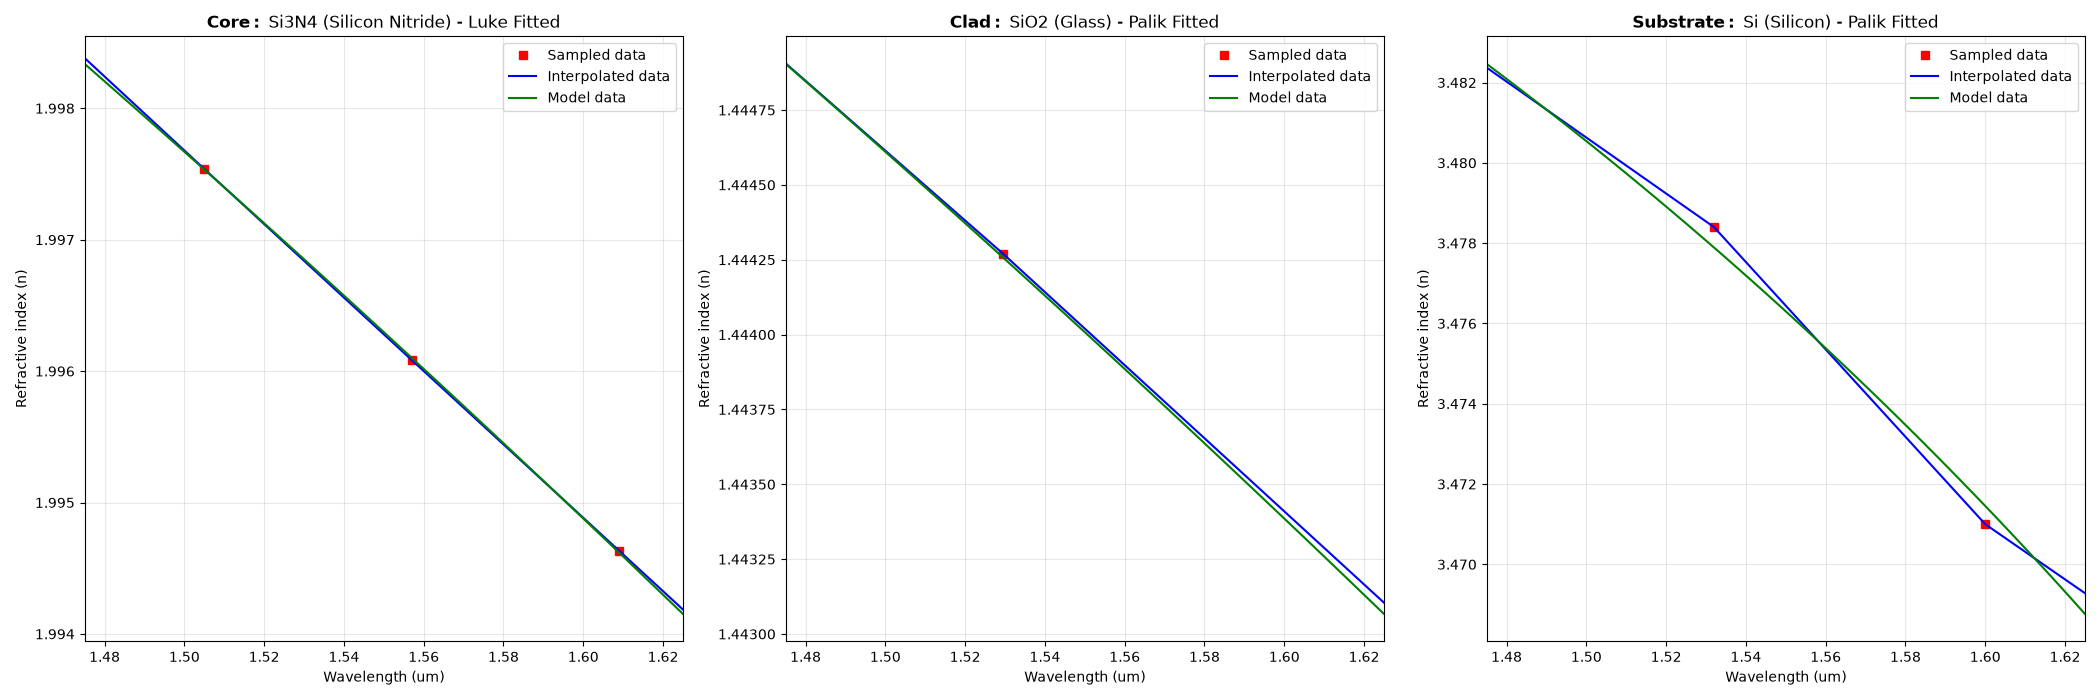

In [9]:
# Materials fit preview

def plot_material(material, ax):
    ax.set_title(material)

    wvl_min = solver.getmaterial(material, "wavelength min")
    wvl_max = solver.getmaterial(material, "wavelength max")

    mat_permitivity_samples = solver.getmaterial(material, "sampled data")

    f1 = mat_permitivity_samples[:, 0]
    mat_n_interpolated = solver.getindex(material, f1).squeeze()
    mat_n_interpolated = np.column_stack((f1, mat_n_interpolated))

    f2 = C / np.linspace(wvl_min, wvl_max, 100)
    fmin = np.min(f2)
    fmax = np.max(f2)
    mat_n_model = solver.getmodeindex(material, f2, 1, 1, 0, fmin, fmax);
    mat_n_model = np.column_stack((f2, mat_n_model))

    px.plot_material_n(
        mat_permitivity_samples,
        mat_n_interpolated,
        mat_n_model=mat_n_model,
        wavelength_min=wvl_min, wavelength_max=wvl_max,
        ax=ax
    )

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7))

# Core
plot_material(core_material, ax1)
ax1.set_title(f"$\\bf{{Core:}}$ {core_material}")

# Clad
plot_material(clad_material, ax2)
ax2.set_title(f"$\\bf{{Clad:}}$ {clad_material}")

# Substrate
plot_material(substrate_material, ax3)
ax3.set_title(f"$\\bf{{Substrate:}}$ {substrate_material}")

fig.tight_layout()
plt.show()

# Structures

Once the material properties have been defined, the geometry of the structures under investigation must be specified. \
The following section describes the creation of the substrate slab, cladding layers, and the complete directional coupler structure. \
Classic directional coupler consist:
- Two paraller waveguides responsible for main coupling region.
- Four S-bends acting as connectors to main coupling region.

| Parameter               | Expression         |
| :---------------------- | :------------------|
| **substrate_thickness** | 100 µm (hardcoded) |
| **substrate:x_span**    | 100 µm (hardcoded) |
| **substrate:y_span**    | 100 µm (hardcoded) |
| **clad:x_span**         | 100 µm (hardcoded) |
| **clad:y_span**         | 100 µm (hardcoded) |

In [10]:
# Structures

substrate_thickness = 100*um

def import_gds(
    filename,
    cellname, 
    objname):
    solver.gdsimport(
        filename,
        cellname,
        1,
        core_material,
        -core_thickness / 2,
        core_thickness / 2
    )
    solver.set("name", objname)
    
    vertices = solver.getnamed(f"{objname}::poly", "vertices")
    x_span = np.max(vertices[:, 0]) - np.min(vertices[:, 0])
    y_span = np.max(vertices[:, 1]) - np.min(vertices[:, 1])

    return x_span, y_span

# Clad
remove("clad")
clad_thickness = bottom_clad_thickness + core_thickness + top_clad_thickness
clad_center_z = (top_clad_thickness - bottom_clad_thickness) / 2
solver.addrect(
    name="clad",
    x=0, y=0, z=clad_center_z,
    x_span=100*um, y_span=100*um, z_span=clad_thickness,
    material=clad_material,
    alpha=0.3,
)

# Substrate
remove("substrate")
substrate_z_max = clad_center_z - clad_thickness/2
substrate_z_min = substrate_z_max - substrate_thickness
solver.addrect(
    name="substrate",
    x=0, y=0, z_max=substrate_z_max, z_min=substrate_z_min,
    x_span=100*um, y_span=100*um,
    material=substrate_material,
    alpha=0.8,
)

# Coupler group
remove("coupler")
solver.addstructuregroup(name="coupler")

# Core 1
remove("core1")
core1_y = -(core_width + coupler_gap)/2
solver.addrect(
    name="core1",
    x=0, x_span=coupler_length,
    y=core1_y, y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)
solver.addtogroup("coupler")

# # Core 2
remove("core2")
core2_y = +(core_width + coupler_gap)/2
solver.addrect(
    name="core2",
    x=0, x_span=coupler_length,
    y=core2_y, y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)
solver.addtogroup("coupler")

# S-bend 1
remove("s-bend1")
print(f"S-bend GDS file: {s_bend_gds}")
sbend_length, sbend_width = import_gds(s_bend_gds, "s-bend", "s-bend1")
print(f"{sbend_length}, {sbend_width}")
solver.setnamed(
    "s-bend1", {
        "second axis": "y",
        "rotation 2": 180,
        "x": -(coupler_length/2 + sbend_length/2),
        "y": +(coupler_gap/2 + sbend_width/2),
    }
)
port1 = (
    -(coupler_length/2 + sbend_length),
    +(coupler_gap/2 + sbend_width - core_width/2)
)

# S-bend 2
remove("s-bend2")
copy("s-bend1", "s-bend2")
solver.setnamed(
    "s-bend2", {
        "first axis": "x",
        "rotation 1": 180,
        "y": -(coupler_gap/2 + sbend_width/2),
    }
)
port2 = (
    -(coupler_length/2 + sbend_length),
    -(coupler_gap/2 + sbend_width - core_width/2)
)

# # S-bend 3
remove("s-bend3")
copy("s-bend1", "s-bend3")
solver.setnamed(
    "s-bend3", {
        "second axis": "y",
        "rotation 2": 0,
        "x": +(coupler_length/2 + sbend_length/2),
    }
)
port3 = (
    +(coupler_length/2 + sbend_length),
    +(coupler_gap/2 + sbend_width - core_width/2)
)

# S-bend 4
remove("s-bend4")
copy("s-bend3", "s-bend4")
solver.setnamed(
    "s-bend4", {
        "first axis": "x",
        "rotation 1": 180,
        "y": -(coupler_gap/2 + sbend_width/2),
    }
)
port4 = (
    +(coupler_length/2 + sbend_length),
    -(coupler_gap/2 + sbend_width - core_width/2)
)

remove("waveguide1")
solver.addrect(
    name="waveguide1",
    x_max=port1[0], x_min=port1[0] - 10*um,
    y=port1[1], y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)

remove("waveguide2")
solver.addrect(
    name="waveguide2",
    x_max=port2[0], x_min=port2[0] - 10*um,
    y=port2[1], y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)

remove("waveguide3")
solver.addrect(
    name="waveguide3",
    x_min=port3[0], x_max=port3[0] + 10*um,
    y=port3[1], y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)

remove("waveguide4")
solver.addrect(
    name="waveguide4",
    x_min=port4[0], x_max=port4[0] + 10*um,
    y=port4[1], y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)

S-bend GDS file: /workspace/GDS/si3n4_w1000nm_h360nm_sbendGA_w5um_l20um.gds
2e-05, 6e-06


# Simulation setup

In order to get transmission throught the structure, **FDTD solver** has been employed. \
All boundry conditions are left with default settings which results in **PML**. 

<img src="assets/stripWaveguide_directionalCoupler_fdtd_simulation.png" width="800">


In [11]:
# Simulation setup

initial_fdtd_length = np.abs(port1[0]) + np.abs(port3[0]) + 2*ports_offset + fde_buffer
initial_fdtd_width = np.abs(port1[1]) + np.abs(port2[1]) + initial_ports_width + fde_buffer

solver.switchtolayout()

# FDTD
remove("FDTD")
solver.addfdtd(
    x=0, x_span=initial_fdtd_length, 
    y=0, y_span=initial_fdtd_width,
    z=0, z_span=initial_fdtd_height
)

solver.setdevice("GPU")
solver.setglobalsource("wavelength start", wavelength_center - wavelength_span/2)
solver.setglobalsource("wavelength stop", wavelength_center + wavelength_span/2)

# Port1
remove("port1")
solver.addport(
    name="port1",
    injection_axis="x-axis",
    x=port1[0] - ports_offset,
    y=port1[1], y_span=initial_ports_width,
    z=0, z_span=initial_ports_height,
    direction="Forward",
    mode_selection="fundamental TE mode",
);

# Port2
remove("port2")
solver.addport(
    name="port2",
    injection_axis="x-axis",
    x=port2[0] - ports_offset,
    y=port2[1], y_span=initial_ports_width,
    z=0, z_span=initial_ports_height,
    direction="Forward",
    mode_selection="fundamental TE mode",
);

# Port3
remove("port3")
solver.addport(
    name="port3",
    injection_axis="x-axis",
    x=port3[0] + ports_offset,
    y=port3[1], y_span=initial_ports_width,
    z=0, z_span=initial_ports_height,
    direction="Backward",
    mode_selection="fundamental TE mode",
);

# Port4
remove("port4")
solver.addport(
    name="port4",
    injection_axis="x-axis",
    x=port4[0] + ports_offset,
    y=port4[1], y_span=initial_ports_width,
    z=0, z_span=initial_ports_height,
    direction="Backward",
    mode_selection="fundamental TE mode",
);

solver.setnamed("FDTD::ports", "override global monitor settings", False)

# Index monitor
remove("index-monitor")
solver.addindex(
    name="index-monitor",
    monitor_type="2D Z-normal",
    x=0, x_span=initial_fdtd_length, 
    y=0, y_span=initial_fdtd_width,
    z=0,
)

# Field monitor
remove("field-monitor")
solver.adddftmonitor(
    name="field-monitor",
    monitor_type="2D Z-normal",
    x=0, x_span=initial_fdtd_length,
    y=0, y_span=initial_fdtd_width,
    z=0,
)

solver.setglobalmonitor("frequency points", 30)

# Global mesh
solver.setnamed("FDTD", "mesh accuracy", 2)

solver.save(f"/tmp/{experiment_name}.fsp")

print_summary(solver)


Simulation region size:
FDTD:x_span = 53.700 µm
FDTD:y_span = 16.950 µm
FDTD:z_span = 3.710 µm

Boundry conditions:
FDTD:x_min_bc = PML
FDTD:x_max_bc = PML
FDTD:y_min_bc = PML
FDTD:y_max_bc = PML
FDTD:z_min_bc = PML
FDTD:z_max_bc = PML

Global source:
wavelength_start = 1475.0 nm
wavelength_stop = 1625.0 nm
center_wavelength  = 1550.0 nm
wavelength_span = 150.0 nm
    


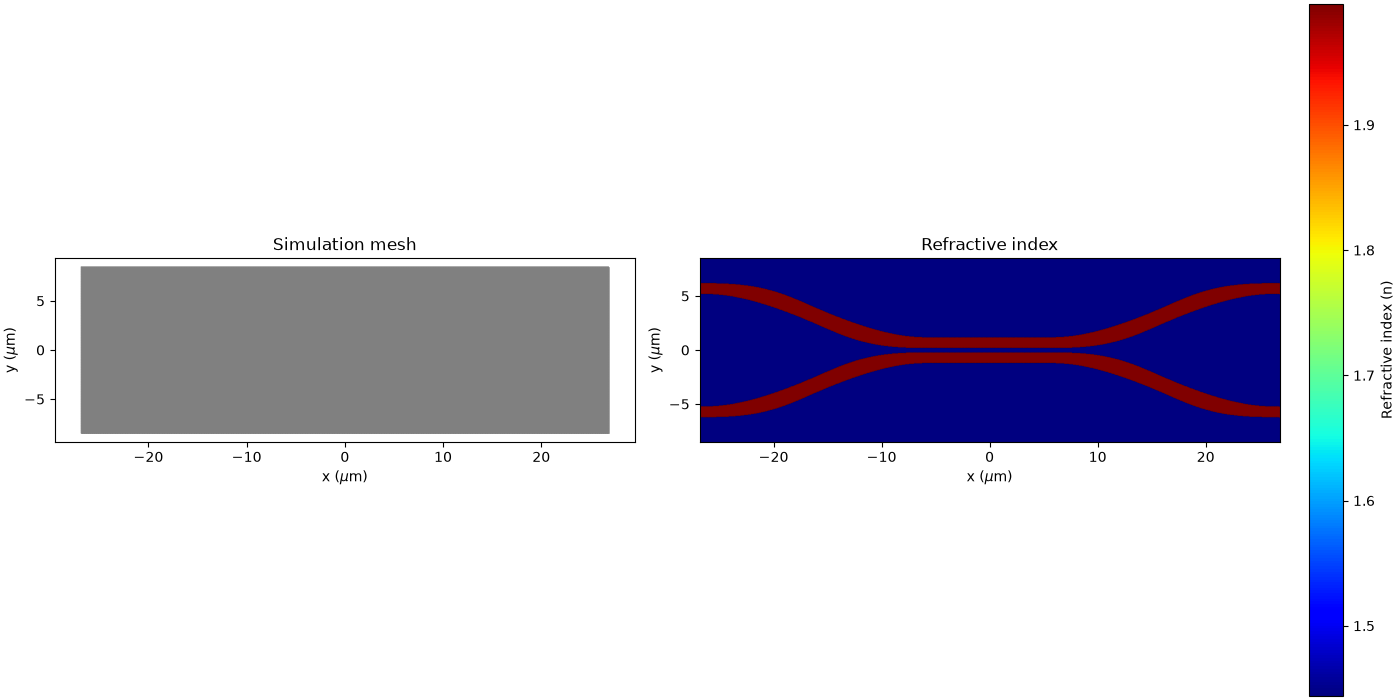

In [12]:
# Simulation preview

index = solver.getresult("index-monitor", "index preview")
index_x, index_y, index_z = [np.squeeze(index[f"index_{a}"]) for a in ["x", "y", "z"]]
x, y = np.squeeze(index["x"]), np.squeeze(index["y"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

# Grid
X, Y = np.meshgrid(x, y, indexing='ij')
ax1.plot(X * 1e6, Y * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.plot(X.T * 1e6, Y.T * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.set_title('Simulation mesh')
ax1.set_xlabel(r'x ($\mu$m)')
ax1.set_ylabel(r'y ($\mu$m)')
ax1.set_aspect('equal')

# Refractive index
im2 = px.plot_field(
    Fx=index_x,
    x=x*1e6, y=y*1e6,
    ax=ax2,
    scale="lin",
)
ax2.set_title('Refractive index')
im2.colorbar.set_label('Refractive index (n)')

solver.setnamed("index-monitor", "enabled", False)

# FDTD Simulation

Cell below runs actual simulation.
Mesh accuracy is set to `2` to provide quick preview of results.

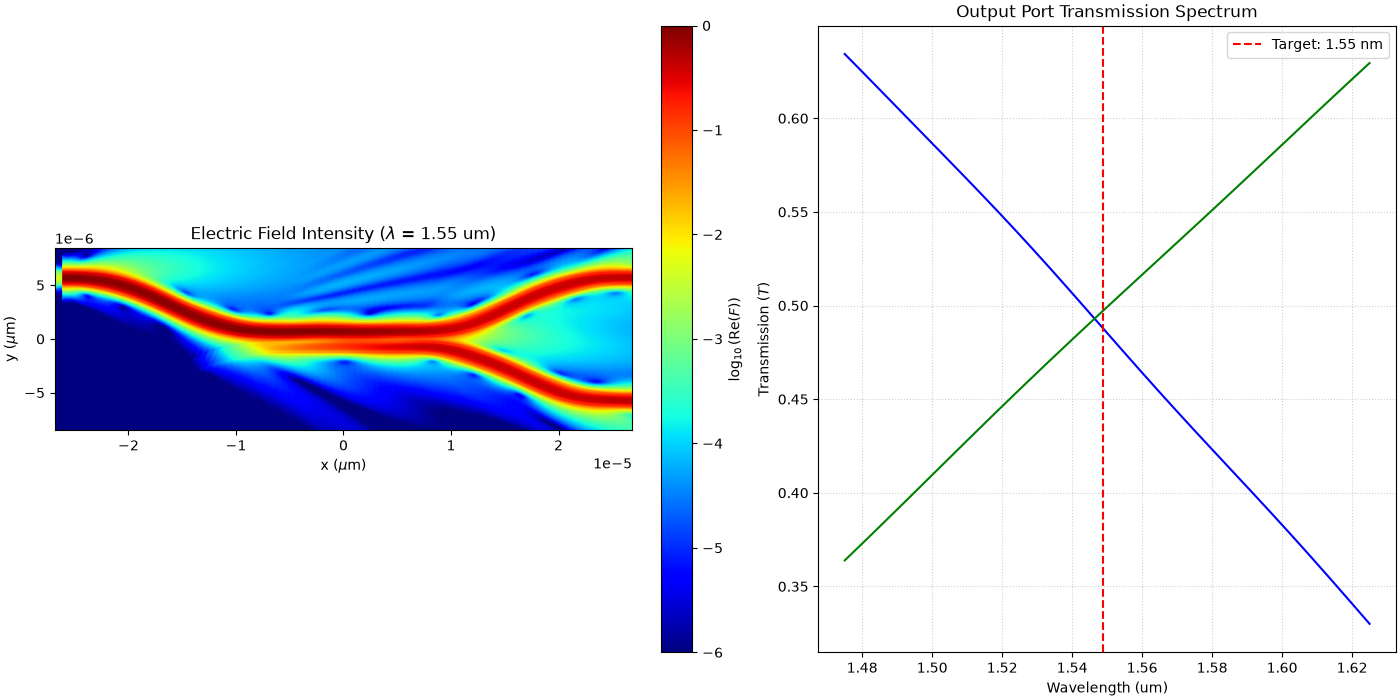

In [13]:
# Initial simulation

solver.run()

# Get E fields components from field-monitor
E = solver.getresult("field-monitor", "E")

# Get index of wavelength nearest center
lambdas = np.squeeze(E["lambda"])
lambda_idx = np.argmin(np.abs(lambdas - wavelength_center))
plot_wavelength = lambdas[lambda_idx]

Ex, Ey, Ez = [np.squeeze(E["E"][..., lambda_idx,i ]) for i in range(3)]
x, y = np.squeeze(E["x"]), np.squeeze(E["y"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

# Efield
px.plot_field(
    Ex, Ey, Ez, 
    x=x, y=y,
    vmin=-6, vmax=0,
    ax=ax1
)
ax1.set_title(rf'Electric Field Intensity ($\lambda$ = {plot_wavelength*1e6:.2f} um)')

# Transmission
T3 = solver.getresult("FDTD::ports::port3", "T")
wavelengths = np.squeeze(T3["lambda"])
T3 = np.squeeze(T3["T"])

T4 = solver.getresult("FDTD::ports::port4", "T")
T4 = np.squeeze(T4["T"])


ax2.plot(wavelengths*1e6, T3, color='b')
ax2.plot(wavelengths*1e6, T4, color='g')
ax2.axvline(plot_wavelength*1e6, color='r', linestyle='--', label=f'Target: {plot_wavelength*1e6:.2f} nm')
ax2.set_xlabel('Wavelength (um)')
ax2.set_ylabel('Transmission ($T$)')
ax2.set_title('Output Port Transmission Spectrum')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.show()

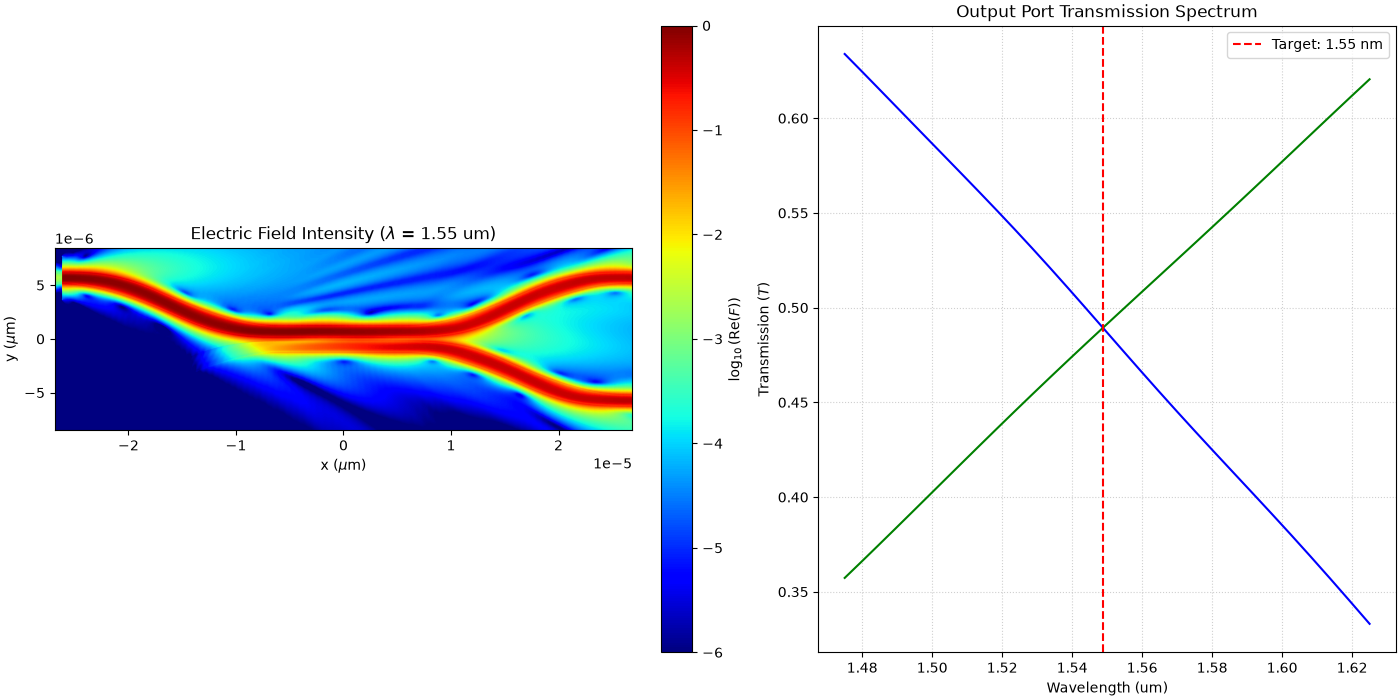

In [15]:
# Second simulation (denser mesh)

solver.switchtolayout()
solver.setnamed("FDTD", "mesh accuracy", 3)
solver.setnamed("index-monitor", "enabled", False)

solver.run()

# Get E fields components from field-monitor
E = solver.getresult("field-monitor", "E")

# Get index of wavelength nearest center
lambdas = np.squeeze(E["lambda"])
lambda_idx = np.argmin(np.abs(lambdas - wavelength_center))
plot_wavelength = lambdas[lambda_idx]

Ex, Ey, Ez = [np.squeeze(E["E"][..., lambda_idx,i ]) for i in range(3)]
x, y = np.squeeze(E["x"]), np.squeeze(E["y"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

# Efield
px.plot_field(
    Ex, Ey, Ez, 
    x=x, y=y,
    vmin=-6, vmax=0,
    ax=ax1
)
ax1.set_title(rf'Electric Field Intensity ($\lambda$ = {plot_wavelength*1e6:.2f} um)')

# Transmission
T3 = solver.getresult("FDTD::ports::port3", "T")
wavelengths = np.squeeze(T3["lambda"])
T3 = np.squeeze(T3["T"])

T4 = solver.getresult("FDTD::ports::port4", "T")
T4 = np.squeeze(T4["T"])


ax2.plot(wavelengths*1e6, T3, color='b')
ax2.plot(wavelengths*1e6, T4, color='g')
ax2.axvline(plot_wavelength*1e6, color='r', linestyle='--', label=f'Target: {plot_wavelength*1e6:.2f} nm')
ax2.set_xlabel('Wavelength (um)')
ax2.set_ylabel('Transmission ($T$)')
ax2.set_title('Output Port Transmission Spectrum')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.show()

In [ ]:
# S-parameters

sweep_name = solver.addsweep(3)
solver.setsweep(sweep_name, "excite all ports", 1)
solver.setsweep(sweep_name, "auto symmetry", 1)
solver.runsweep("s-parameter sweep", "GPU");

# Export S-parameters
solver.exportsweep("s-parameter sweep", f"results/{experiment_name}.dat", "lumerical")
